In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("housing_regression.csv")

df.head()

,Area_sqft,Bedrooms,Bathrooms,Property_Age_years,Distance_to_City_Center_km,Parking_Spaces,Neighborhood_Score_1_to_10,Price_INR
0,857,1,1,12,6.0,0,3.0,17172515
1,3596,7,6,8,15.4,2,4.1,74140796
2,3118,5,4,31,9.0,1,3.6,62282514
3,2255,3,3,9,29.7,0,9.0,45275859
4,2232,4,4,7,26.6,2,7.9,46323817


In [3]:
X = df[['Area_sqft']]
y = df[['Price_INR']]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
model = LinearRegression()

In [6]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[19700.81]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Area_sqft']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[700542.52]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [8]:
y_pred = model.predict(X_test)
y_pred

array([[20145238.81200266],
       [75346899.39991269],
       [16283880.68379768],
       ...,
       [73711732.43745853],
       [76056128.4438687 ],
       [70204988.83123155]])

In [9]:
from sklearn.metrics import mean_squared_error

r2 = model.score(X_test, y_test)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("R - squared:", round(r2, 4))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

R - squared: 0.9946
MSE: 2856162475616.64
RMSE: 1690018.48


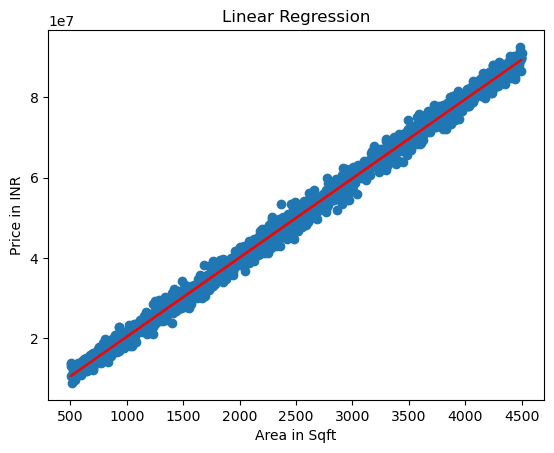

In [10]:
plt.scatter(X_test, y_test)

plt.plot(X_test, y_pred, color='red')

plt.xlabel("Area in Sqft")
plt.ylabel("Price in INR")

plt.title("Linear Regression")

plt.show()